# 4. Open question

**Research question.** In the communities of the Horizon Europe collaboration network, are the most central organisations evenly distributed across geographic areas? If not, is the difference explained by the number of projects each organisation takes part in, or does it remain when comparing organisations with the same number of projects?

**Approach.** The question is addressed in three steps.
1. *Communities.* We detect the communities of the network with three algorithms and compare them. One partition is kept as reference, and we evaluate its stability, its quality and its modularity against the null model.
2. *Central organisations.* Inside every large community we measure the centrality of each organisation, and compare how each geographic area (region) is represented among all members and among the most central ones.
3. *Number of projects.* We compare the centrality of organisations with the same number of projects, and the observed results with those of the null model, to check whether a region is under-represented only because its organisations take part in fewer projects.

**Comparison term.** Every project links all its participants to each other, so dense groups and highly connected organisations can appear even when partners are chosen at random. The results are therefore compared with a null model that keeps the construction: the same projects and the same organisations, each with the same number of projects of similar size, and partners assigned at random.

**Data.** Two inputs, both from Horizon Europe:
- the network built in `02_build_network.ipynb`, with the country of each organisation as node attribute and the number of shared projects as edge weight;
- the participations, cleaned and saved in `02_build_network.ipynb`, used to count the projects of each organisation and to build the null model.

## Imports and configuration

In [1]:
import random
from pathlib import Path

import igraph as ig
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import ConvexHull

# Cleaned participations saved by 02_build_network.ipynb
PART_DIR = Path("../data/participations")
# Network built in 02_build_network.ipynb
NET_DIR = Path("../data/network")
# Output folder for the figures
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Random seed, so that communities and null networks are reproducible
SEED = 42

# Number of runs of the Louvain algorithm on the observed network
N_LOUVAIN_RUNS = 10
# Number of null networks generated as comparison term
N_NULL_NETWORKS = 20

# Centre of a community: the 1% of its members with the most links inside the community
CENTRE_FRACTION = 0.01
# Smallest community analysed: with 1,000 members its centre has 10 organisations
MIN_COMMUNITY_SIZE = 1000

# Organisations are grouped by number of projects, to compare those with a similar participation
PROJECT_BANDS = ["1", "2", "3", "4-5", "6-9", "10-19", "20-49", "50+"]
BAND_UPPER_LIMITS = [1, 2, 3, 5, 9, 19, 49, np.inf]

# Projects are grouped by number of participants: the null model reassigns an organisation among projects of the same class
SIZE_CLASSES = ["2", "3", "4-5", "6-9", "10-19", "20-49", "50+"]
SIZE_UPPER_LIMITS = [2, 3, 5, 9, 19, 49, np.inf]

## Data

### Network, participations and number of projects

We load the network of `02_build_network.ipynb` and the participations it was built from, keeping only the projects with at least two participants, since the others generate no edges. Organisations are grouped by number of projects, and projects by number of participants.

In [2]:
# Nodes and edges of the network built in 02_build_network.ipynb
nodes = pd.read_csv(NET_DIR / "nodes.csv.gz", keep_default_na=False, na_values=[""])
edges = pd.read_csv(NET_DIR / "edges.csv.gz")

# True for the organisations with at least one link, False for the isolated ones
has_links = nodes["id"].isin(pd.concat([edges["source"], edges["target"]])).to_numpy()

# Participations cleaned in 02_build_network.ipynb: one row per organisation-project pair
participations = pd.read_csv(PART_DIR / "participations.csv.gz")

# Only the projects with at least two participants generate edges
n_participants = participations.groupby("projectID")["organisationID"].transform("size")
collaborative = participations[n_participants >= 2].copy()

# Size class of the project of every participation, used by the null model
collaborative["size_class"] = pd.cut(n_participants[n_participants >= 2], [1] + SIZE_UPPER_LIMITS, labels=SIZE_CLASSES).astype(str)

# Number of collaborative projects of every organisation, in the same order as the rows of the node table
activity = collaborative.groupby("organisationID").size().reindex(nodes["id"]).fillna(0).astype(int).to_numpy()

# Group of every organisation by number of projects (isolated organisations belong to none)
band = np.asarray(pd.cut(activity, [0] + BAND_UPPER_LIMITS, labels=PROJECT_BANDS).astype(str))

print(f"nodes:                             {len(nodes):>8}")
print(f"edges:                             {len(edges):>8}")
print(f"collaborative projects:            {collaborative['projectID'].nunique():>8}")
print(f"participations in these projects:  {len(collaborative):>8}")
print(f"organisations in these projects:   {(activity > 0).sum():>8}")

nodes:                                35200
edges:                              1061382
collaborative projects:               12541
participations in these projects:    134559
organisations in these projects:      34382


### Regions

Countries are grouped into the four European regions of the United Nations geoscheme (M49): Western, Northern, Southern and Eastern Europe. Cyprus and Kosovo, which M49 does not place in Europe, are assigned to Southern Europe. All the other countries form a fifth group, *Rest of the world*.

In [3]:
# European regions of the UN geoscheme (M49), by CORDIS country code, with Cyprus (CY) and Kosovo (XK) added to Southern Europe.
# CORDIS uses EL for Greece and UK for the United Kingdom, instead of the ISO codes GR and GB
REGIONS = {
    "Western Europe": ["AT", "BE", "CH", "DE", "FR", "LI", "LU", "MC", "NL"],
    "Northern Europe": ["AX", "DK", "EE", "FI", "FO", "GG", "IE", "IM", "IS", "JE", "LT", "LV", "NO", "SE", "SJ", "UK"],
    "Southern Europe": ["AD", "AL", "BA", "CY", "EL", "ES", "GI", "HR", "IT", "ME", "MK", "MT", "PT", "RS", "SI", "SM", "VA", "XK"],
    "Eastern Europe": ["BG", "BY", "CZ", "HU", "MD", "PL", "RO", "RU", "SK", "UA"],
}

# The five groups, and the colour of each in the figures
REGION_NAMES = list(REGIONS) + ["Rest of the world"]
REGION_COLORS = dict(zip(REGION_NAMES, ["#1f4e79", "#7f9c3a", "#e08b2c", "#c0504d", "#9a9a9a"]))

# Region and country of every organisation, in the same order as the rows of the node table.
# Countries that are in no region, or missing, go to Rest of the world
region_of = {code: name for name, codes in REGIONS.items() for code in codes}
region = nodes["country"].map(region_of).fillna("Rest of the world").to_numpy()
country = nodes["country"].fillna("unknown").to_numpy()

# Number of organisations with at least one link in each region, and percentage of the total
linked_by_region = pd.Series(region[has_links]).value_counts().reindex(REGION_NAMES)
print("Organisations with at least one link, by region:")
print(pd.DataFrame({"organisations": linked_by_region,
                    "percentage": (100 * linked_by_region / linked_by_region.sum()).round(1)}).to_string())

# Six most frequent countries of each group, with their number of organisations
print("\nMost frequent countries in each group (number of organisations):")
for name in REGION_NAMES:
    top = pd.Series(country[has_links & (region == name)]).value_counts().head(6)
    print(f"  {name:18}" + "".join(f"{c:>6} {n:<5}" for c, n in top.items()))

Organisations with at least one link, by region:
                   organisations  percentage
Western Europe             11747        34.2
Northern Europe             5987        17.4
Southern Europe             9840        28.6
Eastern Europe              3059         8.9
Rest of the world           3749        10.9

Most frequent countries in each group (number of organisations):
  Western Europe        DE 3484     FR 2864     NL 1897     BE 1637     AT 925      CH 800  
  Northern Europe       UK 1704     SE 871      NO 724      FI 722      DK 705      IE 567  
  Southern Europe       ES 3313     IT 2825     EL 1215     PT 934      SI 402      HR 335  
  Eastern Europe        PL 767      RO 529      CZ 475      HU 369      BG 359      UA 297  
  Rest of the world     US 607      TR 518      CN 192      IL 191      CA 159      JP 103  


## Method

### Functions to build the networks

The first function turns a table of participations into an edge table, with the rule of `02_build_network.ipynb`: all the participants of a project are linked to each other, and the weight of a link is the number of projects the two organisations share. It is used for the null networks, since the edge table of the observed network is loaded from file. The second turns an edge table into a graph, and is used for both.

In [4]:
def project_network(participation_table):
    """Return the edge table of a set of participations: one row per pair of organisations
    that share at least one project, with the number of shared projects as weight."""
    table = participation_table[["projectID", "organisationID"]].drop_duplicates()
    table = table.sort_values(["projectID", "organisationID"])
    table = table.assign(n=table.groupby("projectID")["organisationID"].transform("size"))
    sources, targets = [], []

    # Projects with the same number of participants are processed together: one row per project, one column per participant
    for n, group in table[table["n"] >= 2].groupby("n"):
        members = group["organisationID"].to_numpy().reshape(-1, n)
        i, j = np.triu_indices(n, 1)                 # all the pairs of participants
        sources.append(members[:, i].ravel())
        targets.append(members[:, j].ravel())

    # A pair that appears in several projects gives one edge, whose weight is the number of shared projects
    pairs = pd.DataFrame({"source": np.concatenate(sources), "target": np.concatenate(targets)})
    return pairs.groupby(["source", "target"]).size().rename("weight").reset_index()


# Position of every organisation in the node table, used as vertex number in igraph
position = pd.Series(np.arange(len(nodes)), index=nodes["id"])

def build_graph(edge_table):
    """Return the weighted undirected graph of an edge table. All the organisations are vertices,
    including the isolated ones, numbered as the rows of the node table."""
    pairs = np.column_stack([position.reindex(edge_table["source"]).to_numpy(),
                             position.reindex(edge_table["target"]).to_numpy()])
    graph = ig.Graph(n=len(nodes), edges=pairs.tolist(), directed=False)
    graph.es["weight"] = edge_table["weight"].tolist()
    return graph


# Graph of the observed network
G = build_graph(edges)

### The null model

A null network is obtained by reassigning the organisations at random among projects of the same size class, that is, with a similar number of participants. Every project keeps its number of participants, and every organisation keeps the number and the size class of its projects: how much it participates does not change, only with whom. Since the reassignment ignores the country, in a null network two organisations with the same participation are equally likely to be central, wherever they are based.

As a check, we build one null network and count how many projects and organisations keep their numbers unchanged.

In [5]:
def shuffle_participations(participation_table, seed):
    """Return a copy of the participations in which the organisations are reassigned at random
    among the projects of the same size class. Every project keeps its number of participants,
    and every organisation keeps the number and the size class of its projects."""
    rng = np.random.default_rng(seed)
    shuffled = participation_table.copy()
    shuffled["organisationID"] = participation_table.groupby("size_class")["organisationID"].transform(
        lambda ids: rng.permutation(ids.to_numpy()))

    # An organisation assigned twice to the same project is counted once
    return shuffled.drop_duplicates(["projectID", "organisationID"])


# One null network, to check what the reassignment preserves
example = shuffle_participations(collaborative, SEED)
same_size = (example.groupby("projectID").size() == collaborative.groupby("projectID").size()).mean()
same_activity = (example.groupby("organisationID").size() == collaborative.groupby("organisationID").size()).mean()

print("Unchanged after the reassignment:")
print(f"  {'participants per project':32}{same_size:>6.1%}")
print(f"  {'projects per organisation':32}{same_activity:>6.1%}")

Unchanged after the reassignment:
  participants per project         95.7%
  projects per organisation        99.2%


Almost all the projects and the organisations keep their numbers. The few differences arise because an organisation assigned twice to the same project is counted once.

### Functions of the analysis

The functions used in the rest of the notebook. All except the quality measures are also applied to every null network.

- **Communities.** Louvain on the weighted network. Only communities with at least 1,000 organisations are analysed.
- **Agreement.** Normalised mutual information (NMI) between two labelings of the same organisations: 0 if independent, 1 if identical.
- **Centrality.** The *internal degree* is the number of links of an organisation towards members of its own community, each counted once whatever its weight. Its *centrality percentile* is its rank among the members of the community by internal degree, divided by their number: it goes from 0 to 1, and members with the same internal degree have the same percentile.
- **Quality.** *Internal edge density*: fraction of the possible links among members that exist. *Conductance*: fraction of the links of the members that lead outside the community.
- **Centre.** The 1% of the members of a community with the highest internal degree.
- **Summary.** The percentage of each region among the members and among the central organisations, the percentage of each country among the central organisations, and the *gap at equal number of projects* of each region: the average difference between the percentile of its organisations and that of all the organisations with a similar number of projects.

In [6]:
def louvain(graph, seed):
    """Return the Louvain community of every organisation, on the weighted graph.
    The seed makes the result reproducible."""
    random.seed(seed)
    return np.array(graph.community_multilevel(weights="weight").membership)


def nmi(a, b):
    """Return the normalised mutual information between two labelings of the same organisations."""
    return ig.compare_communities(pd.factorize(a)[0].tolist(), pd.factorize(b)[0].tolist(), method="nmi")


def internal_degree(graph, membership):
    """Return, for every organisation, the number of its links towards members of its own community."""
    ends = np.array(graph.get_edgelist())
    inside = membership[ends[:, 0]] == membership[ends[:, 1]]
    return np.bincount(ends[inside].ravel(), minlength=graph.vcount())


def community_quality(graph, membership):
    """Return size, internal edge density and conductance of every large community."""
    ends = np.array(graph.get_edgelist())
    a, b = membership[ends[:, 0]], membership[ends[:, 1]]
    n_communities = membership.max() + 1
    sizes = np.bincount(membership, minlength=n_communities)

    # Links inside each community, and links that leave it
    internal = np.bincount(a[a == b], minlength=n_communities)
    leaving = np.bincount(np.concatenate([a[a != b], b[a != b]]), minlength=n_communities)

    large = np.where(sizes >= MIN_COMMUNITY_SIZE)[0]
    return pd.DataFrame({"size": sizes[large],
                         "internal edge density": 2 * internal[large] / (sizes[large] * (sizes[large] - 1)),
                         "conductance": leaving[large] / (2 * internal[large] + leaving[large])}, index=large)


def positions(membership, centrality):
    """Return one row per organisation of a large community: community, centrality, centrality percentile,
    whether it is in the centre, region, country, number of projects and group by number of projects."""
    sizes = np.bincount(membership)
    keep = np.where(sizes[membership] >= MIN_COMMUNITY_SIZE)[0]
    table = pd.DataFrame({"community": membership[keep], "centrality": centrality[keep], "region": region[keep],
                          "country": country[keep], "activity": activity[keep], "band": band[keep]}, index=keep)

    # Centrality percentile: rank among the members of the community, divided by their number
    table["percentile"] = table.groupby("community")["centrality"].rank(pct=True)

    # Centre: the 1% of the members of each community with the highest centrality
    rank = table.groupby("community")["centrality"].rank(ascending=False, method="first")
    table["centre"] = rank <= (table.groupby("community")["centrality"].transform("size") * CENTRE_FRACTION).round()
    return table


def summarise(table):
    """Return the summaries of a table of positions used in the analysis, by region and by country."""
    # Fraction of each region among all the organisations, and among those in the centre of a community
    members = table["region"].value_counts(normalize=True).reindex(REGION_NAMES).fillna(0)
    centre = table.loc[table["centre"], "region"].value_counts(normalize=True).reindex(REGION_NAMES).fillna(0)

    # Gap at equal number of projects: how much more or less central the organisations of a region are,
    # on average, than all the organisations with a similar number of projects
    gap = (table["percentile"] - table.groupby("band")["percentile"].transform("mean")).groupby(table["region"]).mean()

    return {"members": members, "centre": centre, "gap": gap.reindex(REGION_NAMES),
            "centre_by_country": table.loc[table["centre"], "country"].value_counts(normalize=True)}

### Null networks

We generate twenty null networks, each with its own seed, and compute on each the quantities that the following sections compare with the observed ones: the modularity of its communities, their agreement with country and region, and the summary of the positions of the organisations. The communities of a null network are detected with one execution of Louvain.

In [7]:
# Quantities computed on every null network
null_modularity, null_nmi_country, null_nmi_region, null_summaries = [], [], [], []

for run in range(N_NULL_NETWORKS):
    # Null network: same projects and organisations, partners assigned at random among projects of the same size class
    graph = build_graph(project_network(shuffle_participations(collaborative, SEED + run)))

    # Communities of the null network, and organisations that are not isolated in it
    membership = louvain(graph, SEED + run)
    linked = np.array(graph.degree()) > 0

    # Modularity of the communities, and their agreement with country and region
    null_modularity.append(graph.modularity(membership.tolist(), weights="weight"))
    null_nmi_country.append(nmi(country[linked], membership[linked]))
    null_nmi_region.append(nmi(region[linked], membership[linked]))

    # Position of the organisations inside the large communities, summarised by region and by country
    null_summaries.append(summarise(positions(membership, internal_degree(graph, membership))))

## 1. Communities

### Three algorithms

We detect communities in the weighted network with three algorithms, based on three different definitions of community: Louvain (*internal density*), Infomap (*entity closeness*) and Label Propagation (*percolation*). Louvain is run ten times with different seeds, and the partition with the highest modularity is kept as the *reference partition*.

For each algorithm we report the number of communities, how many are large, the modularity, and the internal edge density and conductance of the large ones. We then measure the agreement (NMI) between each pair of partitions.

In [8]:
# Louvain is repeated with different seeds: the reference partition is the repetition with the highest modularity
repetitions = [louvain(G, SEED + run) for run in range(N_LOUVAIN_RUNS)]
modularities = [G.modularity(m.tolist(), weights="weight") for m in repetitions]
reference = repetitions[int(np.argmax(modularities))]

# The three partitions of the observed network
partitions = {"Louvain": reference}
random.seed(SEED)
partitions["Infomap"] = np.array(G.community_infomap(edge_weights="weight").membership)
random.seed(SEED)
partitions["Label Propagation"] = np.array(G.community_label_propagation(weights="weight").membership)

# One row per algorithm: the communities it finds, and the quality of the large ones
found, quality_of_large = {}, {}
for name, membership in partitions.items():
    sizes = np.bincount(membership[has_links])
    large = sizes[sizes >= MIN_COMMUNITY_SIZE]
    quality = community_quality(G, membership)
    found[name] = {"communities": (sizes > 0).sum(),
                   "large communities": len(large),
                   "% of organisations in large communities": round(100 * large.sum() / has_links.sum(), 1),
                   "modularity": round(G.modularity(membership.tolist(), weights="weight"), 3)}
    quality_of_large[name] = {"average internal edge density": round(quality["internal edge density"].mean(), 3),
                              "average conductance": round(quality["conductance"].mean(), 3),
                              "highest conductance": round(quality["conductance"].max(), 3)}

print("Communities found by each algorithm:")
print(pd.DataFrame.from_dict(found, orient="index").to_string())
print("\nQuality of the large communities of each algorithm:")
print(pd.DataFrame.from_dict(quality_of_large, orient="index").to_string())

# Agreement (NMI) between each pair of partitions, on the organisations with at least one link
print("\nAgreement between partitions (NMI):")
names = list(partitions)
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        pair = f"{names[i]} - {names[j]}"
        print(f"  {pair:32}{nmi(partitions[names[i]][has_links], partitions[names[j]][has_links]):.3f}")

The history saving thread hit an unexpected error (OperationalError('database is locked')).History will not be written to the database.
Communities found by each algorithm:
                   communities  large communities  % of organisations in large communities  modularity
Louvain                     72                  7                                     90.3       0.414
Infomap                   1046                  2                                     20.9       0.342
Label Propagation          160                  1                                     95.3       0.032

Quality of the large communities of each algorithm:
                   average internal edge density  average conductance  highest conductance
Louvain                                    0.012                0.429                0.511
Infomap                                    0.023                0.468                0.511
Label Propagation                          0.002                0.008                0.00

Louvain has the highest modularity (0.414) and divides 90% of the organisations into seven large communities. Infomap returns a much finer partition and agrees with Louvain only in part (NMI = 0.41): its two large communities are denser, but no better separated (average conductance 0.47 against 0.43). Label Propagation puts 95% of the organisations in a single community.

The three algorithms give three different pictures of the same network. Louvain is kept as the reference partition, because it is the only one that divides most of the organisations into several large communities.

### Stability of the reference partition

Louvain can give a different partition at every execution. We compare the other nine repetitions with the reference partition: their agreement (NMI), the number of large communities they find and their modularity. The rest of the analysis is based on the reference partition. The repetitions are used again in Section 2, to check that the main result does not depend on it.

In [9]:
# Agreement of the other repetitions with the reference partition
agreement = [nmi(reference[has_links], m[has_links]) for m in repetitions if m is not reference]

# Number of large communities found by each repetition
n_large = [(np.bincount(m[has_links]) >= MIN_COMMUNITY_SIZE).sum() for m in repetitions]

# Minimum, mean and maximum of each quantity over the repetitions
print(f"Louvain repeated {N_LOUVAIN_RUNS} times\n")
print(f"{'':38}{'min':>7}{'mean':>7}{'max':>7}")
print(f"{'Agreement with the reference (NMI)':38}{np.min(agreement):>7.3f}{np.mean(agreement):>7.3f}{np.max(agreement):>7.3f}")
print(f"{'Modularity':38}{np.min(modularities):>7.3f}{np.mean(modularities):>7.3f}{np.max(modularities):>7.3f}")
print(f"{'Number of large communities':38}{np.min(n_large):>7}{np.mean(n_large):>7.1f}{np.max(n_large):>7}")

Louvain repeated 10 times

                                          min   mean    max
Agreement with the reference (NMI)      0.497  0.531  0.595
Modularity                              0.408  0.412  0.414
Number of large communities                 6    7.2      8


The repetitions find a similar number of large communities and almost the same modularity (0.408–0.414), but they assign the organisations differently: their agreement with the reference partition is moderate.

### Quality of the large communities

For each large community of the reference partition we report the size, the internal edge density and the conductance. Communities are named after their most central organisation.

In [10]:
# Size, internal edge density and conductance of the large communities of the reference partition
quality = community_quality(G, reference)

# Every community is named after its member with the highest internal degree
reference_degree = internal_degree(G, reference)
community_names = {}
for community in quality.index:
    members = np.where(reference == community)[0]
    community_names[community] = nodes["name"].iloc[members[np.argmax(reference_degree[members])]][:36]

print("Large communities of the reference partition:")
print(quality.rename(index=community_names).sort_values("size", ascending=False).round(3).to_string())

Large communities of the reference partition:
                                      size  internal edge density  conductance
ETHNIKO KENTRO EREVNAS KAI TECHNOLOG  7540                  0.004        0.394
CENTRE NATIONAL DE LA RECHERCHE SCIE  6672                  0.006        0.471
FRAUNHOFER GESELLSCHAFT ZUR FORDERUN  5171                  0.006        0.447
WAGENINGEN UNIVERSITY                 4372                  0.007        0.426
INSTITUT NATIONAL DE LA SANTE ET DE   4123                  0.012        0.391
HELLENIC CENTRE FOR MARINE RESEARCH   2000                  0.013        0.511
INDRA SISTEMAS SA                     1159                  0.038        0.362


In every large community more than a third of the links of the members go to other communities, and in one more than half. The communities are recognisable, but not sharply separated.

### Modularity against the null networks

Linking all the participants of every project can create dense groups even when partners are assigned at random. We therefore compare the modularity of the reference partition with that of the communities found in the null networks.

In [11]:
# Modularity of the observed network, compared with that of the null networks
observed_modularity = G.modularity(reference.tolist(), weights="weight")
ratio = observed_modularity / np.mean(null_modularity)

print(f"Modularity of the observed network: {observed_modularity:.3f}\n")
print(f"Modularity of the {N_NULL_NETWORKS} null networks:")
print(f"{'mean':>8}{'min':>8}{'max':>8}")
print(f"{np.mean(null_modularity):>8.3f}{np.min(null_modularity):>8.3f}{np.max(null_modularity):>8.3f}")
print(f"\nRatio between observed and null mean: {ratio:.1f}")

Modularity of the observed network: 0.414

Modularity of the 20 null networks:
    mean     min     max
   0.202   0.199   0.204

Ratio between observed and null mean: 2.1


The null networks reach about half of the observed modularity, even though their partners are assigned at random. Half of the modularity therefore comes from how the network is built, with all the participants of a project linked to each other. Only the other half reflects how organisations actually choose their partners.

### Communities and geography

Before looking at the centre, we check whether the communities follow geography. We measure the agreement (NMI) between the reference partition and the country or region of the organisations, and report for each large community the percentage of its members in every region.

In [12]:
# Agreement between the communities and the country or region of the organisations, observed and in the null networks
print("Agreement between communities and geography (NMI):")
print(f"{'':10}{'observed':>10}{'null mean':>11}{'null max':>10}")
for label, values, null_values in [("country", country, null_nmi_country), ("region", region, null_nmi_region)]:
    print(f"{label:10}{nmi(values[has_links], reference[has_links]):>10.3f}{np.mean(null_values):>11.3f}{np.max(null_values):>10.3f}")

# Table of the organisations of the large communities, with their position inside the community
table = positions(reference, reference_degree)

# Percentage of the members of every large community in each region, from the largest community to the smallest
composition = 100 * pd.crosstab(table["community"], table["region"], normalize="index").reindex(columns=REGION_NAMES)
composition.insert(0, "size", table["community"].value_counts())
composition = composition.sort_values("size", ascending=False).rename(index=community_names)

# Last row: all the large communities together
composition.loc["All large communities"] = [len(table)] + list(100 * table["region"].value_counts(normalize=True).reindex(REGION_NAMES))
composition["size"] = composition["size"].astype(int)
composition = composition.rename_axis(index=None, columns=None)
print("\nMembers of the large communities by region (%):")
print(composition.to_string(float_format="{:.1f}".format))

Agreement between communities and geography (NMI):
            observed  null mean  null max
country        0.054      0.017     0.019
region         0.025      0.001     0.001

Members of the large communities by region (%):
                                       size  Western Europe  Northern Europe  Southern Europe  Eastern Europe  Rest of the world
ETHNIKO KENTRO EREVNAS KAI TECHNOLOG   7540            29.6             16.4             39.8             9.4                4.8
CENTRE NATIONAL DE LA RECHERCHE SCIE   6672            35.9             16.0             21.3             9.0               17.7
FRAUNHOFER GESELLSCHAFT ZUR FORDERUN   5171            44.7             18.3             25.0             5.3                6.7
WAGENINGEN UNIVERSITY                  4372            29.2             14.7             33.1            10.3               12.7
INSTITUT NATIONAL DE LA SANTE ET DE    4123            36.8             19.2             21.8             6.1               16.2


Communities do not follow geography: their agreement with country and region is higher than in the null networks, but close to zero. Every large community has members from all the regions, in different proportions. We can therefore ask which regions hold the centre of each community.

## 2. Are the central organisations evenly distributed across regions?

For each region we compare two percentages: how much it weighs among all the members of the large communities, and how much among their central organisations. The ratio between the two is 1 when the region is as present in the centres as among the members, above 1 when it is over-represented, below 1 when it is under-represented.

Since Louvain gives a different partition at every execution, the last column reports the lowest and the highest ratio found in the ten repetitions.

In [13]:
# Summary of the reference partition by region
observed = summarise(table)

# Percentage of each region among all the members of the large communities, and among their central organisations
result = pd.DataFrame({"% of members": 100 * observed["members"],
                       "% of central organisations": 100 * observed["centre"]})

# Ratio between the two percentages: 1 means that the region is as present in the centres as among the members
result["ratio"] = result["% of central organisations"] / result["% of members"]

# Number of central organisations of each region
result["central organisations"] = table.loc[table["centre"], "region"].value_counts().reindex(REGION_NAMES).fillna(0).astype(int)

# The same ratio in each of the ten repetitions of Louvain: lowest and highest value
repeated = [summarise(positions(m, internal_degree(G, m))) for m in repetitions]
ratios = pd.DataFrame([r["centre"] / r["members"] for r in repeated])
result["ratio in the ten repetitions"] = [f"{low:.2f} - {high:.2f}" for low, high in zip(ratios.min(), ratios.max())]

print(f"Large communities: {table['community'].nunique()}")
print(f"Organisations:     {len(table)}, of which {table['centre'].sum()} in the centres\n")
print(result.rename_axis(None).to_string(formatters={"% of members": "{:.1f}".format,
                                                     "% of central organisations": "{:.1f}".format,
                                                     "ratio": "{:.2f}".format}))

Large communities: 7
Organisations:     31037, of which 311 in the centres

                  % of members % of central organisations ratio  central organisations ratio in the ten repetitions
Western Europe            34.6                       39.2  1.13                    122                  1.04 - 1.15
Northern Europe           17.0                       17.4  1.02                     54                  0.97 - 1.13
Southern Europe           29.1                       37.3  1.28                    116                  1.24 - 1.40
Eastern Europe             8.6                        5.1  0.60                     16                  0.28 - 0.61
Rest of the world         10.7                        1.0  0.09                      3                  0.00 - 0.12


Southern Europe is the most over-represented region among the central organisations (ratio 1.28), followed by Western Europe (1.13), while Northern Europe is present in proportion to its members. Eastern Europe has 8.6% of the members but 5.1% of the central organisations, and the rest of the world is almost absent (3 out of 311).

The direction of these results is the same in all ten repetitions, except for Northern Europe, which varies between 0.97 and 1.13. For Eastern Europe the reference partition is close to the most favourable case: its ratio goes from 0.28 to 0.61.

### The centres, community by community

The table above puts the seven communities together. Here we look at each centre separately: for every community, how many of its central organisations belong to each region. The communities are numbered from the largest to the smallest. We also count the links among the central organisations, and how many of them join two different communities.

In [14]:
# Central organisations of the reference partition, from the most to the least connected inside their community
centres = table[table["centre"]].sort_values("centrality", ascending=False)

# Communities numbered from the largest to the smallest: the numbers are the labels used in the figure
n_central = centres["community"].value_counts()
number = {c: i + 1 for i, c in enumerate(n_central.index)}

# Number of central organisations of each region in every community, with the name of its most connected member
by_region = pd.crosstab(centres["community"], centres["region"]).reindex(index=n_central.index, columns=REGION_NAMES, fill_value=0)
by_region.insert(0, "most connected member", [community_names[c] for c in by_region.index])
by_region.index = [number[c] for c in by_region.index]
print("Central organisations by community and region:")
print(by_region.rename_axis(index=None, columns=None).to_string())

# Links among the central organisations (igraph keeps the nodes of a subgraph in their original order)
core_ids = np.sort(centres.index.to_numpy())
core = G.induced_subgraph(core_ids.tolist())
core_ends = np.array(core.get_edgelist())
core_community = table.loc[core_ids, "community"].to_numpy()
first, second = core_community[core_ends[:, 0]], core_community[core_ends[:, 1]]
print(f"\nLinks among the central organisations: {core.ecount()}, that is {core.density():.0%} of the possible pairs")
print(f"Links that join central organisations of two different communities: {(first != second).mean():.0%}")

Central organisations by community and region:
                  most connected member  Western Europe  Northern Europe  Southern Europe  Eastern Europe  Rest of the world
1  ETHNIKO KENTRO EREVNAS KAI TECHNOLOG              12                4               57               2                  0
2  CENTRE NATIONAL DE LA RECHERCHE SCIE              28               15               21               3                  0
3  FRAUNHOFER GESELLSCHAFT ZUR FORDERUN              28                6               12               4                  2
4                 WAGENINGEN UNIVERSITY              19               10               11               4                  0
5  INSTITUT NATIONAL DE LA SANTE ET DE               22               11                6               1                  1
6   HELLENIC CENTRE FOR MARINE RESEARCH               6                6                6               2                  0
7                     INDRA SISTEMAS SA               7                2      

The figure shows the same organisations. Each point is a central organisation, coloured by region, and each contour encloses the centre of one community. Inside a contour, organisations are placed by a force-directed layout, and the links drawn are those between organisations that share at least three projects. Between two contours, a single line summarises the links: the thicker it is, the larger the share of their central organisations that are linked.

The names in the table are long legal names. For the figure we shorten them by hand: the abbreviations in the next cell are written after reading the table, and are used only as labels. Each label keeps the number of its community, so that it can be checked against the table.

Labels used in the figure: 1  CERTH, 2  CNRS, 3  Fraunhofer, 4  Wageningen, 5  INSERM, 6  HCMR, 7  Indra


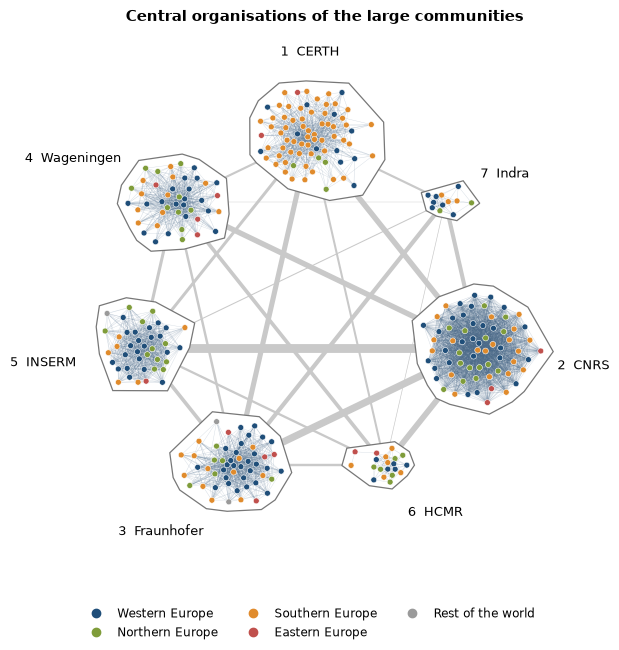

In [15]:
# Abbreviations written by hand, from the table above. Each one is matched with the beginning of the name of the most connected member.
# A community without one keeps its number alone.
ABBREVIATIONS = {"ETHNIKO KENTRO EREVNAS": "CERTH", "CENTRE NATIONAL DE LA RECHERCHE": "CNRS", "FRAUNHOFER": "Fraunhofer",
                 "WAGENINGEN": "Wageningen", "INSTITUT NATIONAL DE LA SANTE": "INSERM", "HELLENIC CENTRE FOR MARINE": "HCMR",
                 "INDRA": "Indra"}

# Label of every community in the figure: its number, followed by the abbreviation when there is one
label = {}
for c in n_central.index:
    found = [short for start, short in ABBREVIATIONS.items() if community_names[c].startswith(start)]
    label[c] = f"{number[c]}  {found[0]}" if found else str(number[c])
print("Labels used in the figure:", ", ".join(label[c] for c in n_central.index))

# Region of every central organisation, in the order of the nodes of the subgraph
region_of_node = table.loc[core_ids, "region"].to_numpy()
weight = np.array(core.es["weight"])

# In the figure the communities are alternated (large, small, large, ...) around a circle
by_size = n_central.index.tolist()
order = [by_size.pop(0) if i % 2 == 0 else by_size.pop() for i in range(len(by_size))]

# The radius of each group grows with the square root of its size; the circle is wide enough to keep neighbours apart
group_radius = {c: 0.9 * np.sqrt(n_central[c]) for c in order}
pairs = zip(order, order[1:] + order[:1])
circle_radius = max(group_radius[a] + group_radius[b] + 4 for a, b in pairs) / (2 * np.sin(np.pi / len(order)))
angles = np.pi / 2 - 2 * np.pi * np.arange(len(order)) / len(order)
group_centre = {c: circle_radius * np.array([np.cos(a), np.sin(a)]) for c, a in zip(order, angles)}

# Inside each group, a force-directed layout of the links among its central organisations, scaled to the group radius
xy = np.zeros((core.vcount(), 2))
for c in order:
    members = np.where(core_community == c)[0]
    sub = core.induced_subgraph(members.tolist())
    random.seed(SEED)
    local = np.array(sub.layout_fruchterman_reingold(weights=sub.es["weight"], niter=2000).coords)
    local -= local.mean(axis=0)
    local *= group_radius[c] / np.linalg.norm(local, axis=1).max()
    xy[members] = group_centre[c] + local

fig, ax = plt.subplots(figsize=(6.4, 6.6))

# Between two groups, one line: its width is the share of the pairs of their central organisations that are linked
for i, a in enumerate(order):
    for b in order[i + 1:]:
        n_links = ((first == a) & (second == b)).sum() + ((first == b) & (second == a)).sum()
        linked = n_links / (n_central[a] * n_central[b])
        ax.plot(*zip(group_centre[a], group_centre[b]), color="#c9c9c9", lw=8 * linked, solid_capstyle="round", zorder=0)

# Inside a group, only the links between organisations that share at least MIN_SHARED projects are drawn
MIN_SHARED = 3
for c, angle in zip(order, angles):

    # White background and contour of the group
    pts = xy[core_community == c]
    hull = pts[ConvexHull(pts).vertices]
    direction = hull - group_centre[c]
    hull = group_centre[c] + direction * 1.12 + 0.6 * direction / np.linalg.norm(direction, axis=1)[:, None]
    ax.fill(*hull.T, facecolor="white", edgecolor="#777777", lw=0.9, zorder=1)

    # Links inside the group
    inside = (first == c) & (second == c) & (weight >= MIN_SHARED)
    for (u, v), w in zip(core_ends[inside], weight[inside]):
        ax.plot(*xy[[u, v]].T, color="#4a6a8a", lw=0.2 + 0.02 * min(w, 30), alpha=0.25, zorder=2)

    # Label of the community, outside its contour
    label_at = group_centre[c] + (group_radius[c] + 2.2) * np.array([np.cos(angle), np.sin(angle)])
    side = "center" if abs(np.cos(angle)) < 0.3 else ("left" if np.cos(angle) > 0 else "right")
    ax.text(*label_at, label[c], ha=side, va="center", fontsize=9.5)

# Organisations, coloured by region
ax.scatter(*xy.T, s=18, c=pd.Series(region_of_node).map(REGION_COLORS), edgecolor="white", linewidth=0.4, zorder=3)
handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=6, color=REGION_COLORS[n], label=n) for n in REGION_NAMES]
fig.legend(handles=handles, frameon=False, fontsize=8.5, loc="lower center", ncol=3)
ax.set_title("Central organisations of the large communities", fontsize=11, fontweight="bold")
ax.set_aspect("equal")
ax.set_axis_off()
ax.margins(0.12)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIG_DIR / "central_organisations_by_community.png", dpi=200)
plt.show()

In the reference partition, the over-representation of Southern Europe comes almost entirely from one community. In community 1 (CERTH), 57 of the 75 central organisations are in Southern Europe. In the other six communities together they are 59 out of 236, a quarter, about the weight of Southern Europe among their members (26%, from the composition table of Section 1). Western Europe has more than half of the central organisations in communities 3 (Fraunhofer) and 5 (INSERM), and only 12 of 75 in community 1.

The centres are not separate groups: 46% of the pairs of central organisations are linked, and 70% of these links join two different communities.

## 3. Is the difference explained by the number of projects?

### From all the organisations to the central ones

A region can be under-represented among the central organisations because its organisations take part in few projects, or because they are less central even when they take part in many. As a first step, we compare the percentage of each region in four totals, all computed on the members of the large communities: the organisations, their participations, the most active organisations and the central organisations. The most active organisations are chosen like the central ones, inside each community: the 1% with the most projects, instead of the 1% with the most links. If the percentage of a region already falls among the most active organisations, its disadvantage is already present in participation. The next two sections check whether the position in the network adds to it.

Percentage of each region among:
                   organisations  participations  1% most active  central organisations
Western Europe              34.6            37.1            36.7                   39.2
Northern Europe             17.0            18.1            19.3                   17.4
Southern Europe             29.1            32.0            40.5                   37.3
Eastern Europe               8.6             6.3             3.2                    5.1
Rest of the world           10.7             6.4             0.3                    1.0

Spearman correlation between number of projects and internal degree:        0.65
Central organisations that are also among the most active of their community: 71.1%


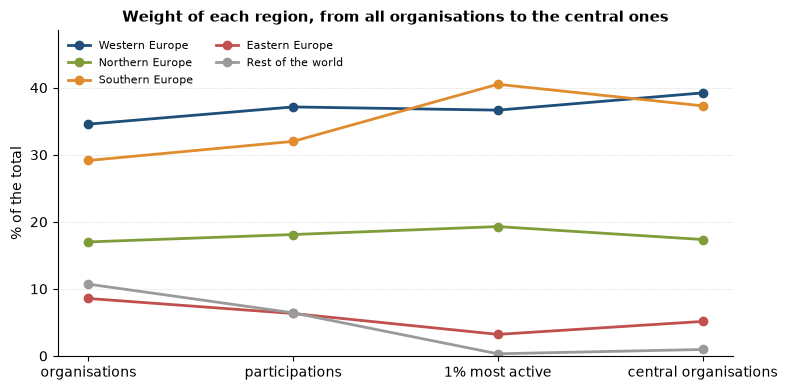

In [16]:
# The 1% of the members of each community with the most projects, chosen with the same rule as the centre
most_active = positions(reference, activity)["centre"]

# Percentage of each region in four totals, all computed on the members of the large communities
steps = 100 * pd.DataFrame({
    "organisations": observed["members"],
    "participations": table.groupby("region")["activity"].sum() / table["activity"].sum(),
    "1% most active": table.loc[most_active, "region"].value_counts(normalize=True),
    "central organisations": observed["centre"],
}).reindex(REGION_NAMES).fillna(0)

print("Percentage of each region among:")
print(steps.rename_axis(None).to_string(float_format="{:.1f}".format))

# How closely the centrality inside the community follows the number of projects
rho = table[["activity", "centrality"]].corr(method="spearman").iloc[0, 1]
overlap = (table["centre"] & most_active).sum() / table["centre"].sum()
print(f"\nSpearman correlation between number of projects and internal degree:        {rho:.2f}")
print(f"Central organisations that are also among the most active of their community: {overlap:.1%}")

# One line per region across the four totals: the slope shows where the percentage of a region falls
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(steps.columns))
for name in REGION_NAMES:
    ax.plot(x, steps.loc[name], marker="o", lw=2, color=REGION_COLORS[name], label=name)
ax.set_xticks(x, steps.columns)
ax.set_ylabel("% of the total")
ax.set_ylim(0, steps.to_numpy().max() * 1.2)
ax.set_title("Weight of each region, from all organisations to the central ones", fontsize=11, fontweight="bold")
ax.grid(True, axis="y", linestyle=":", linewidth=0.6, alpha=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIG_DIR / "regions_from_organisations_to_centre.png", dpi=200)
plt.show()

Three regions are already out of proportion among the most active organisations, even more than among the central ones: Eastern Europe and the rest of the world are under-represented, Southern Europe is over-represented. Western Europe has a larger percentage among the central organisations than among the most active ones, Northern Europe a smaller one.

Centrality is related to the number of projects, but does not coincide with it: their correlation is 0.65, and 71% of the central organisations are also among the most active of their community.

### Centrality at equal number of projects

We now compare organisations with the same number of projects. For each group by number of projects, we compute the average centrality percentile of the organisations of each region. If the differences came only from the number of projects, organisations of different regions would be equally central in the same group.

Average centrality percentile, by region (rows) and number of projects (columns):
                                 1     2     3   4-5   6-9  10-19  20-49   50+
Western Europe               0.378 0.570 0.682 0.779 0.865  0.920  0.963 0.991
Northern Europe              0.358 0.562 0.687 0.779 0.860  0.927  0.963 0.987
Southern Europe              0.365 0.576 0.694 0.762 0.867  0.928  0.965 0.989
Eastern Europe               0.380 0.588 0.709 0.786 0.861  0.932  0.972 0.989
Rest of the world            0.352 0.519 0.649 0.740 0.832  0.882  0.927 0.962
Largest difference in Europe 0.022 0.025 0.027 0.025 0.007  0.012  0.009 0.004

Number of organisations:
                      1     2    3  4-5  6-9  10-19  20-49  50+
Western Europe     6559  1620  708  645  495    360    208  134
Northern Europe    3501   721  316  254  191    128     91   75
Southern Europe    5281  1431  637  592  446    346    209  105
Eastern Europe     1638   394  174  169  139    101     34   11
Rest of the world  

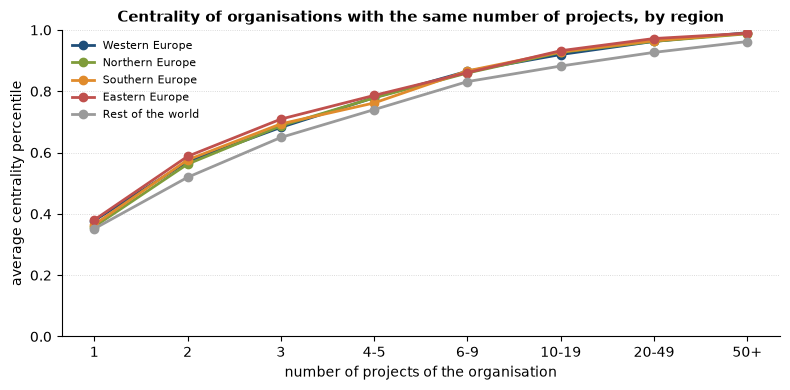

In [17]:
# Average centrality percentile of the organisations of each region, by number of projects
by_band = table.pivot_table(index="region", columns="band", values="percentile", aggfunc="mean")
by_band = by_band.reindex(index=REGION_NAMES, columns=PROJECT_BANDS)

# Number of organisations behind each average
counts = table.pivot_table(index="region", columns="band", values="percentile", aggfunc="size")
counts = counts.reindex(index=REGION_NAMES, columns=PROJECT_BANDS).fillna(0).astype(int)

# Last row: largest difference between the four European regions, for each number of projects
european = by_band.loc[REGION_NAMES[:4]]
with_difference = by_band.copy()
with_difference.loc["Largest difference in Europe"] = european.max() - european.min()

print("Average centrality percentile, by region (rows) and number of projects (columns):")
print(with_difference.rename_axis(index=None, columns=None).to_string(float_format="{:.3f}".format))
print("\nNumber of organisations:")
print(counts.rename_axis(index=None, columns=None).to_string())

# One line per region: if the lines overlap, regions are equally central at equal number of projects
fig, ax = plt.subplots(figsize=(8, 4))
for name in REGION_NAMES:
    ax.plot(PROJECT_BANDS, by_band.loc[name], marker="o", lw=2, color=REGION_COLORS[name], label=name)
ax.set_xlabel("number of projects of the organisation")
ax.set_ylabel("average centrality percentile")
ax.set_ylim(0, 1)
ax.set_title("Centrality of organisations with the same number of projects, by region", fontsize=11, fontweight="bold")
ax.grid(True, axis="y", linestyle=":", linewidth=0.6, alpha=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "centrality_at_equal_number_of_projects.png", dpi=200)
plt.show()

At equal number of projects, the four European regions are almost equally central: their averages never differ by more than 0.03, and Eastern Europe is never the lowest of the four. What Eastern Europe lacks is very active organisations: only 0.4% of its organisations have 50 projects or more (11 out of 2,660), against 1.2% in Western and Southern Europe. The rest of the world is the only group below the others in every column.

### Comparison with the null networks

Two results are compared with the null networks, where every organisation keeps the number and the size class of its projects, and partners are assigned ignoring the country.

- **Gap at equal number of projects.** It is zero when the organisations of a region are as central as the others with a similar number of projects.
- **Central organisations.** The percentage of the central organisations that belong to each region. In the null networks it shows what participation alone would produce.

With twenty null networks, a value just outside their range is not evidence of a difference: even when there is none, about one value in ten falls outside by chance. Only large deviations are interpreted.

Gap at equal number of projects (difference in centrality percentile):
                   observed  null mean  null min  null max
Western Europe       +0.007     +0.004    +0.001    +0.006
Northern Europe      -0.007     +0.003    -0.003    +0.007
Southern Europe      +0.000     +0.003    +0.001    +0.007
Eastern Europe       +0.014     +0.006    +0.002    +0.010
Rest of the world    -0.024     -0.030    -0.040    -0.023

Percentage of the central organisations in each region:
                   observed  null mean  null min  null max
Western Europe         39.2       38.4      36.5      40.9
Northern Europe        17.4       22.1      18.0      24.5
Southern Europe        37.3       33.9      31.1      37.6
Eastern Europe          5.1        3.8       1.6       5.5
Rest of the world       1.0        1.7       0.8       3.1


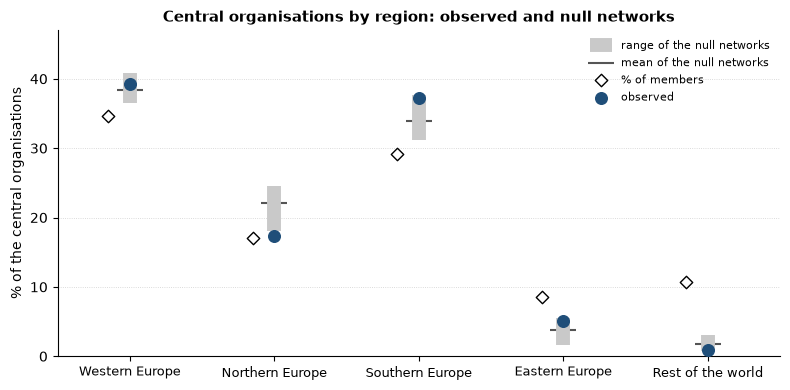

In [18]:
def null_range(key):
    """Return mean, minimum and maximum over the null networks of one of the summaries by region."""
    values = pd.DataFrame([summary[key] for summary in null_summaries])
    return values.mean(), values.min(), values.max()


# Gap at equal number of projects of each region: observed, and in the null networks
mean, low, high = null_range("gap")
gap_table = pd.DataFrame({"observed": observed["gap"], "null mean": mean, "null min": low, "null max": high})
print("Gap at equal number of projects (difference in centrality percentile):")
print(gap_table.rename_axis(None).to_string(float_format="{:+.3f}".format))

# Percentage of the central organisations that belong to each region: observed, and in the null networks
mean, low, high = null_range("centre")
centre_table = 100 * pd.DataFrame({"observed": observed["centre"], "null mean": mean, "null min": low, "null max": high})
centre_table.insert(0, "% of members", 100 * observed["members"])
print("\nPercentage of the central organisations in each region:")
print(centre_table.drop(columns="% of members").rename_axis(None).to_string(float_format="{:.1f}".format))

# For each region: range of the null networks (bar), their mean (tick), observed value (dot), percentage of members (diamond, to the left)
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(REGION_NAMES))
ax.vlines(x, centre_table["null min"], centre_table["null max"], color="#c9c9c9", lw=10, label="range of the null networks")
ax.scatter(x, centre_table["null mean"], marker="_", s=350, color="#555555", label="mean of the null networks")
ax.scatter(x - 0.15, centre_table["% of members"], marker="D", s=40, facecolor="white", edgecolor="black", zorder=3, label="% of members")
ax.scatter(x, centre_table["observed"], s=70, color="#1f4e79", zorder=4, label="observed")
ax.set_xticks(x, REGION_NAMES, fontsize=9)
ax.set_xlim(-0.5, len(REGION_NAMES) - 0.5)
ax.set_ylabel("% of the central organisations")
ax.set_ylim(0, centre_table.to_numpy().max() * 1.15)
ax.set_title("Central organisations by region: observed and null networks", fontsize=11, fontweight="bold")
ax.grid(True, axis="y", linestyle=":", linewidth=0.6, alpha=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "central_organisations_by_region_vs_null.png", dpi=200)
plt.show()

For every region the observed gap is close to that of the null networks: it differs from their mean by 0.01 at most. Four gaps are outside the null range, which is very narrow, but by a few thousandths. The negative gap of the rest of the world is reproduced: it comes from the number and the size of the projects of its organisations, not from whom they take part with.

For the central organisations, four regions out of five are within the range of the null networks. They include Eastern Europe and the rest of the world: their under-representation is what their participation produces. Only Northern Europe is outside, with fewer central organisations than in any null network.

### Countries

The comparison of the central organisations is repeated by country, to see which countries are behind the result by region. The table lists the countries with at least 1% of the central organisations, observed or on average in the null networks, sorted by the difference between the two. It marks those whose observed percentage is outside the range of the null networks, and the figure shows the same comparison.

Central organisations by country (% of all the central organisations)
Countries with at least 1%. Difference: observed minus null mean, in percentage points.

country   observed  null mean    null range  difference   outside the null range
EL             9.3        5.8     4.2 - 7.4        +3.6   above
ES            13.2       11.7   10.1 - 13.9        +1.5   
NL             8.4        6.9     5.5 - 8.2        +1.5   above
NO             3.5        2.5     1.5 - 4.1        +1.0   
BE             6.1        5.1     4.0 - 6.1        +1.0   
AT             4.2        3.2     2.2 - 4.7        +0.9   
CZ             1.9        1.2     0.4 - 2.1        +0.7   
RO             1.3        0.7     0.0 - 1.5        +0.6   
CH             3.5        3.1     1.9 - 4.8        +0.4   
PL             1.6        1.2     0.0 - 3.1        +0.4   
CY             1.3        0.9     0.3 - 2.0        +0.3   
SE             3.5        3.3     2.4 - 4.1        +0.2   
DK             1.9        2.0     0.8 - 2.

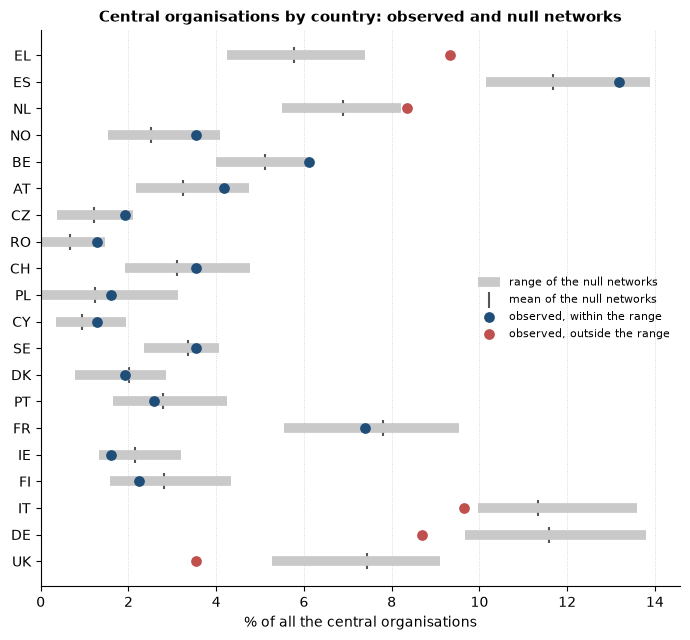

In [19]:
# Percentage of the central organisations in each country: observed, and in every null network
observed_country = 100 * observed["centre_by_country"]
null_country = 100 * pd.DataFrame([summary["centre_by_country"] for summary in null_summaries]).fillna(0)

countries = pd.DataFrame({"observed": observed_country, "null mean": null_country.mean(),
                          "null min": null_country.min(), "null max": null_country.max()}).fillna(0)

# Only the countries with at least 1% of the central organisations, observed or in the null networks
countries = countries[(countries["observed"] >= 1) | (countries["null mean"] >= 1)]

# Difference between observed and null mean, and position with respect to the range of the null networks
countries["difference"] = countries["observed"] - countries["null mean"]
countries["outside the null range"] = np.where(countries["observed"] > countries["null max"], "above",
                                      np.where(countries["observed"] < countries["null min"], "below", ""))

# One row per country, from the largest positive difference to the largest negative one
shown = countries.sort_values("difference", ascending=False)

print("Central organisations by country (% of all the central organisations)")
print("Countries with at least 1%. Difference: observed minus null mean, in percentage points.\n")
print(f"{'country':8}{'observed':>10}{'null mean':>11}{'null range':>14}{'difference':>12}   outside the null range")
for code, row in shown.iterrows():
    null_range_text = f"{row['null min']:.1f} - {row['null max']:.1f}"
    print(f"{code:8}{row['observed']:>10.1f}{row['null mean']:>11.1f}{null_range_text:>14}{row['difference']:>+12.1f}   {row['outside the null range']}")

print(f"\nCountries: {len(countries)}, of which outside the range of the null networks: {(countries['outside the null range'] != '').sum()}")

# One row per country: range of the null networks (bar), their mean (tick) and observed value (dot)
fig, ax = plt.subplots(figsize=(7, 6.5))
y = np.arange(len(shown))[::-1]
outside = (shown["outside the null range"] != "").to_numpy()
ax.hlines(y, shown["null min"], shown["null max"], color="#c9c9c9", lw=7, label="range of the null networks")
ax.scatter(shown["null mean"], y, marker="|", s=140, color="#555555", label="mean of the null networks")
ax.scatter(shown["observed"][~outside], y[~outside], s=45, color="#1f4e79", zorder=3, label="observed, within the range")
ax.scatter(shown["observed"][outside], y[outside], s=45, color="#c0504d", zorder=3, label="observed, outside the range")
ax.set_yticks(y, shown.index)
ax.set_xlabel("% of all the central organisations")
ax.set_xlim(0, None)
ax.set_title("Central organisations by country: observed and null networks", fontsize=11, fontweight="bold")
ax.grid(True, axis="x", linestyle=":", linewidth=0.6, alpha=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="center right")
fig.tight_layout()
fig.savefig(FIG_DIR / "central_organisations_by_country_vs_null.png", dpi=200)
plt.show()

Five of the 20 countries are outside the range of the null networks, where about two are expected by chance, and three deviations are large. Greece has 9.3% of the central organisations against 5.8% in the null networks. The United Kingdom has about half of what its participation would give (3.5% against 7.4%), and Germany three quarters (8.7% against 11.6%). The Netherlands and Italy are outside the range by less than half a point.

These countries explain the results by region. The United Kingdom accounts for most of the shortfall of Northern Europe (3.9 of 4.7 points), and Greece for the whole difference between Southern Europe and its null mean.

## Answer to the research question

- **Are the most central organisations evenly distributed across regions?** No. Southern and Western Europe are over-represented among the central organisations, Eastern Europe and the rest of the world under-represented, in all ten repetitions of Louvain. In the reference partition the excess of Southern Europe comes almost entirely from one community.
- **Is the difference explained by the number of projects?** For the European regions, yes: organisations with the same number of projects are almost equally central. For the rest of the world a difference remains, and it is reproduced by the null networks, where every organisation also keeps the size class of its projects.
- **What participation does not explain.** Three countries: Greece is above what its participation gives, the United Kingdom and Germany below. Because of the United Kingdom, Northern Europe is the only region with fewer central organisations than in any null network.